## Import Library

In [1]:
#202431122_Ragil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
#Load data
df = pd.read_csv('04_bank_customers.csv', sep=";")
df

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no


In [3]:
#EDA
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [4]:
#202431122_Ragil
#Cek missing value, duplikat, dan distribusi target
print(df.isnull().sum())
print("Jumlah duplikat:", df.duplicated().sum())
print(df['y'].value_counts())

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64
Jumlah duplikat: 0
no     39922
yes     5289
Name: y, dtype: int64


In [5]:
#202431122_Ragil
#Cek nilai unik target dan beberapa fitur kategorikal
df['y'].unique()

array(['no', 'yes'], dtype=object)

In [6]:
df['job'].unique()

array(['management', 'technician', 'entrepreneur', 'blue-collar',
       'unknown', 'retired', 'admin.', 'services', 'self-employed',
       'unemployed', 'housemaid', 'student'], dtype=object)

In [7]:
#202431122_Ragil
#Preprocessing: encoding target
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['y'] = le.fit_transform(df['y'])
print(df['y'].unique())

for i, label in enumerate(le.classes_):
    print(f"{i} = {label}")

[0 1]
0 = no
1 = yes


In [8]:
#202431122_Ragil
#Preprocessing: encoding semua fitur kategorikal
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
print(cat_cols)

for col in cat_cols:
    df[col] = LabelEncoder().fit_transform(df[col])

df

['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,4,1,2,0,2143,1,0,2,5,8,261,1,-1,0,3,0
1,44,9,2,1,0,29,1,0,2,5,8,151,1,-1,0,3,0
2,33,2,1,1,0,2,1,1,2,5,8,76,1,-1,0,3,0
3,47,1,1,3,0,1506,1,0,2,5,8,92,1,-1,0,3,0
4,33,11,2,3,0,1,0,0,2,5,8,198,1,-1,0,3,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45206,51,9,1,2,0,825,0,0,0,17,9,977,3,-1,0,3,1
45207,71,5,0,0,0,1729,0,0,0,17,9,456,2,-1,0,3,1
45208,72,5,1,1,0,5715,0,0,0,17,9,1127,5,184,3,2,1
45209,57,1,1,1,0,668,0,0,1,17,9,508,4,-1,0,3,0


In [9]:
#202431122_Ragil
#Pisahkan fitur dan target
x = df.drop(['y'], axis=1)
x

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome
0,58,4,1,2,0,2143,1,0,2,5,8,261,1,-1,0,3
1,44,9,2,1,0,29,1,0,2,5,8,151,1,-1,0,3
2,33,2,1,1,0,2,1,1,2,5,8,76,1,-1,0,3
3,47,1,1,3,0,1506,1,0,2,5,8,92,1,-1,0,3
4,33,11,2,3,0,1,0,0,2,5,8,198,1,-1,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45206,51,9,1,2,0,825,0,0,0,17,9,977,3,-1,0,3
45207,71,5,0,0,0,1729,0,0,0,17,9,456,2,-1,0,3
45208,72,5,1,1,0,5715,0,0,0,17,9,1127,5,184,3,2
45209,57,1,1,1,0,668,0,0,1,17,9,508,4,-1,0,3


In [10]:
y = df['y']
y

0        0
1        0
2        0
3        0
4        0
        ..
45206    1
45207    1
45208    1
45209    0
45210    0
Name: y, Length: 45211, dtype: int32

In [11]:
#202431122_Ragil
#Train test split
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.25, random_state=0
)

In [12]:
#202431122_Ragil
#Regresi Linear
from sklearn.linear_model import LinearRegression

regressor = LinearRegression()
regressor.fit(x_train, y_train)

LinearRegression()

In [13]:
#202431122_Ragil
# Evaluasi Regresi Linear
# Karena target biner, hasil prediksi kontinu di-threshold 0.5 agar bisa dihitung akurasinya
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score

y_pred_reg = regressor.predict(x_test)
y_pred_reg_class = (y_pred_reg >= 0.5).astype(int)

akurasi_reg = accuracy_score(y_test, y_pred_reg_class)
print("Akurasi Regresi Linear:", akurasi_reg)

print("MSE:", mean_squared_error(y_test, y_pred_reg))
print("R2 Score:", r2_score(y_test, y_pred_reg))

Akurasi Regresi Linear: 0.8871980890029196
MSE: 0.0824324109518239
R2 Score: 0.2034260872944913


In [14]:
#202431122_Ragil
# Decision Tree
from sklearn.tree import DecisionTreeClassifier

classifier = DecisionTreeClassifier(criterion='entropy', max_depth=5, random_state=0)
classifier.fit(x_train, y_train)

DecisionTreeClassifier(criterion='entropy', max_depth=5, random_state=0)

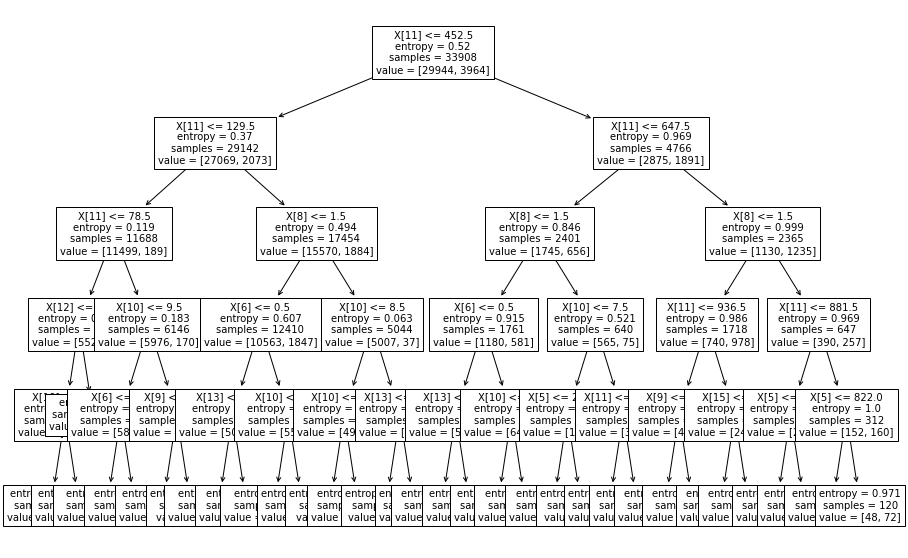

In [15]:
#202431122_Ragil
# Visualisasi Decision Tree
from sklearn import tree

plt.subplots(figsize=(15, 10))
tree.plot_tree(classifier, fontsize=10)
plt.show()

In [16]:
#202431122_Ragil
# Kedalaman Decision Tree
depth = classifier.get_depth()
depth

5

In [17]:
#202431122_Ragil
# Evaluasi Decision Tree
y_pred = classifier.predict(x_test)
akurasi = accuracy_score(y_test, y_pred)
print("Akurasi Decision Tree:", akurasi)

Akurasi Decision Tree: 0.8882597540475979


In [18]:
#202431122_Ragil
# Perbandingan akurasi
print("Akurasi Regresi Linear :", akurasi_reg)
print("Akurasi Decision Tree  :", akurasi)

Akurasi Regresi Linear : 0.8871980890029196
Akurasi Decision Tree  : 0.8882597540475979
